<a href="https://colab.research.google.com/github/IvanMusila/tajirika/blob/ml%2Fcategorizer/02_categorizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tajirika - Notebook 2: Expense Categorizer
Hybrid design: **rules** handle transaction types whose category is fixed (fees, airtime, ...), and a **TF-IDF + Random Forest** model handles merchants (buy goods, paybill, person-to-person sends).

**Run order:** 1 -> 10. Needs `transactions_labeled.csv` from Notebook 1.

## Cell 1 - Imports

In [ ]:
import json, sys, importlib, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from datetime import datetime
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay

## Cell 2 - Mount Drive and set paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/Tajirika'
DATA_CSV   = f'{DRIVE_BASE}/data/transactions_labeled.csv'
MODEL_DIR  = f'{DRIVE_BASE}/models/categorizer'
Path(MODEL_DIR).mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## Cell 3 - Shared feature code
This file is the single source of truth for how features are built and how rules + model combine. The same file gets copied into your FastAPI backend, so training and serving can never drift apart.

In [ ]:
FEATURES_PY = r"""
import numpy as np
import pandas as pd

# Types whose category is fixed. No ML needed.
RULE_TYPES = {
    'fee':             'invisible',
    'loan_repayment':  'invisible',
    'savings_deposit': 'invisible',
    'airtime':         'convenience',
    'data_bundle':     'convenience',
    'withdrawal':      'necessity',
}

def make_features(df):
    # Text = merchant name + transaction type (+ a flag if paid as a small business)
    name = df['merchant_name'].fillna('').astype(str).str.lower()
    ttype = df['transaction_type'].fillna('').astype(str)
    smallbiz = df['details'].fillna('').astype(str).str.contains(
        'Small Business|Micro SME', case=False, regex=True)
    out = pd.DataFrame(index=df.index)
    out['text'] = name + ' ' + ttype + np.where(smallbiz, ' smallbiz', '')
    out['log_amount'] = np.log1p(df['amount'].astype(float))
    return out[['text', 'log_amount']]

def categorize(df, model, threshold=0.6):
    # Rules first, model for the rest. Returns category, confidence, source, needs_review.
    res = pd.DataFrame(index=df.index)
    res['category'] = None
    res['confidence'] = np.nan
    res['source'] = None

    rule_mask = df['transaction_type'].isin(RULE_TYPES)
    res.loc[rule_mask, 'category'] = df.loc[rule_mask, 'transaction_type'].map(RULE_TYPES)
    res.loc[rule_mask, 'confidence'] = 1.0
    res.loc[rule_mask, 'source'] = 'rule'

    ml_mask = ~rule_mask
    if ml_mask.any():
        proba = model.predict_proba(make_features(df[ml_mask]))
        res.loc[ml_mask, 'category'] = model.classes_[proba.argmax(axis=1)]
        res.loc[ml_mask, 'confidence'] = proba.max(axis=1)
        res.loc[ml_mask, 'source'] = 'model'

    res['needs_review'] = (res['source'] == 'model') & (res['confidence'] < threshold)
    return res
"""

Path(f'{MODEL_DIR}/categorizer_features.py').write_text(FEATURES_PY)

if MODEL_DIR not in sys.path:
    sys.path.insert(0, MODEL_DIR)
import categorizer_features as cf
importlib.reload(cf)
print("Feature module ready. Rule types:", list(cf.RULE_TYPES))

Feature module ready. Rule types: ['fee', 'loan_repayment', 'savings_deposit', 'airtime', 'data_bundle', 'withdrawal']


## Cell 4 - Load data and decide what the model learns from
- **Model scope:** merchant-type rows only (buy_goods, paybill, send_money).
- **Trusted labels:** `id_map`, `keyword`, `p2p_rule`. Rows labeled by `default_low_confidence` or `amount_guess` were guesses, so the model must not learn from them.

In [ ]:
df = pd.read_csv(DATA_CSV, parse_dates=['timestamp'])
df = df[df['is_debit']].copy()

MERCHANT_TYPES  = ['buy_goods', 'paybill', 'send_money']
TRUSTED_SOURCES = ['id_map', 'keyword', 'p2p_rule']

ml_df = df[df['transaction_type'].isin(MERCHANT_TYPES)].copy()
pool  = ml_df[ml_df['label_source'].isin(TRUSTED_SOURCES)].copy()     # train + test
guess = ml_df[~ml_df['label_source'].isin(TRUSTED_SOURCES)].copy()    # kept aside

print(f"All expense rows:        {len(df)}")
print(f"Merchant-type rows:      {len(ml_df)}")
print(f"  trusted (train/test):  {len(pool)}")
print(f"  guessed (held aside):  {len(guess)}")
print("\nTrusted label distribution:")
print(pool['category'].value_counts())
print("\nTrusted rows by label source:")
print(pool['label_source'].value_counts())

All expense rows:        5783
Merchant-type rows:      3719
  trusted (train/test):  3562
  guessed (held aside):  157

Trusted label distribution:
category
social          1611
convenience     1072
necessity        464
aspirational     325
invisible         90
Name: count, dtype: int64

Trusted rows by label source:
label_source
p2p_rule    2183
id_map      1234
keyword      145
Name: count, dtype: int64


## Cell 5 - Model definition

In [ ]:
def make_model():
    pre = ColumnTransformer([
        # Character n-grams so unseen merchant names still share pieces with known ones
        ('txt', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4),
                                min_df=2, sublinear_tf=True), 'text'),
        ('num', 'passthrough', ['log_amount']),
    ])
    clf = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                 n_jobs=-1, random_state=42)
    return Pipeline([('pre', pre), ('clf', clf)])

def report(y_true, y_pred, title):
    print(f"\n===== {title} =====")
    print(f"accuracy: {accuracy_score(y_true, y_pred):.3f}   "
          f"macro-F1: {f1_score(y_true, y_pred, average='macro'):.3f}")
    print(classification_report(y_true, y_pred, zero_division=0))

## Cell 6 - Evaluation 1: train on the past, test on the most recent 6 months
A random split would leak your habits into the test set. A time split is the honest test of "will this work on next month's transactions?"
The baseline predicts the most common class every time. The model has to beat it clearly.

Train: 2915 rows (to 2026-04-03)   Test: 647 rows
Baseline macro-F1 (always guess the majority class): 0.116

===== Time split (last 6 months), all rows =====
accuracy: 0.985   macro-F1: 0.974
              precision    recall  f1-score   support

aspirational       0.94      0.95      0.95        64
 convenience       0.98      1.00      0.99       209
   invisible       0.95      1.00      0.97        19
   necessity       0.99      0.93      0.96        90
      social       1.00      1.00      1.00       265

    accuracy                           0.98       647
   macro avg       0.97      0.98      0.97       647
weighted avg       0.98      0.98      0.98       647


===== Time split - MERCHANT ROWS ONLY (buy_goods + paybill) =====
accuracy: 0.962   macro-F1: 0.970
              precision    recall  f1-score   support

aspirational       0.94      0.95      0.95        64
 convenience       0.96      0.99      0.97        87
   invisible       0.95      1.00      0.97        19


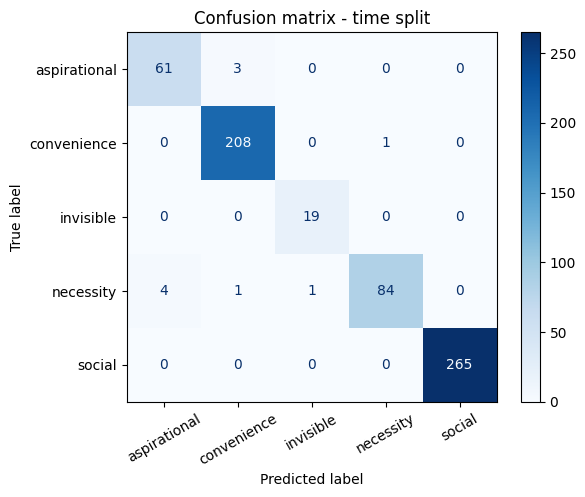

In [ ]:
cutoff = pool['timestamp'].max() - pd.Timedelta(days=180)
train  = pool[pool['timestamp'] <= cutoff]
test   = pool[pool['timestamp'] >  cutoff]
print(f"Train: {len(train)} rows (to {cutoff.date()})   Test: {len(test)} rows")

X_train, y_train = cf.make_features(train), train['category']
X_test,  y_test  = cf.make_features(test),  test['category']

# Baseline
base = Pipeline([('pre', make_model().named_steps['pre']),
                 ('clf', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
base_f1 = f1_score(y_test, base.predict(X_test), average='macro')
print(f"Baseline macro-F1 (always guess the majority class): {base_f1:.3f}")

model_t = make_model().fit(X_train, y_train)
pred_t  = model_t.predict(X_test)
report(y_test, pred_t, "Time split (last 6 months), all rows")

# Headline number: merchant rows only. P2P rows are just the rules we wrote, so they flatter the score.
mer_mask = test['transaction_type'].isin(['buy_goods', 'paybill']).values
report(y_test[mer_mask], pred_t[mer_mask], "Time split - MERCHANT ROWS ONLY (buy_goods + paybill)")
mer_f1_time = f1_score(y_test[mer_mask], pred_t[mer_mask], average='macro')
mer_acc_time = accuracy_score(y_test[mer_mask], pred_t[mer_mask])

# Merchants in the test period that never appeared in training
unseen = ~test['merchant_id'].isin(train['merchant_id'])
print(f"\nTest rows from merchants never seen in training: {unseen.sum()} ({unseen.mean():.0%})")
if unseen.sum() > 0:
    print(f"accuracy on those unseen merchants: "
          f"{accuracy_score(y_test[unseen], pred_t[unseen.values]):.3f}")
    print(f"accuracy on seen merchants:         "
          f"{accuracy_score(y_test[~unseen], pred_t[(~unseen).values]):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, pred_t, xticks_rotation=30, cmap='Blues')
plt.title('Confusion matrix - time split')
plt.show()

## Cell 7 - Evaluation 2: every merchant in the test fold is new (merchant rows only)
Group k-fold keeps all rows of a merchant in the same fold, so the model is always tested on merchants it has never seen. This is the closest proxy for "what happens when another person uses the app?" Person-to-person rows are excluded because they only reflect our own rules.
The confidence table shows the trade-off the app makes: confident predictions are labeled automatically, uncertain ones are sent to the user to label.


===== Unseen merchants - buy_goods + paybill only =====
accuracy: 0.497   macro-F1: 0.357
              precision    recall  f1-score   support

aspirational       0.53      0.10      0.17       325
 convenience       0.50      0.85      0.63       405
   invisible       0.24      0.93      0.38        90
   necessity       0.80      0.49      0.61       464
      social       0.00      0.00      0.00        95

    accuracy                           0.50      1379
   macro avg       0.41      0.47      0.36      1379
weighted avg       0.56      0.50      0.45      1379


If the app auto-labels only confident predictions and asks the user otherwise:
 confidence >= auto-labeled  accuracy on those
           0.0         100%              0.497
           0.4          96%              0.491
           0.5          79%              0.543
           0.6          50%              0.454
           0.7          31%              0.568
           0.8          18%              0.352


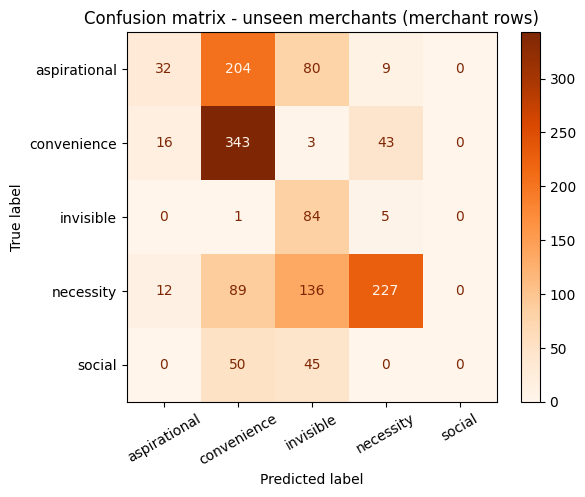

In [ ]:
mer = pool[pool['transaction_type'].isin(['buy_goods', 'paybill'])]
X_g, y_g = cf.make_features(mer), mer['category']
groups   = mer['merchant_id'].astype(str)

proba_g   = cross_val_predict(make_model(), X_g, y_g, groups=groups,
                              cv=GroupKFold(n_splits=5), method='predict_proba')
classes_g = np.array(sorted(y_g.unique()))
pred_g    = classes_g[proba_g.argmax(axis=1)]
conf_g    = proba_g.max(axis=1)

report(y_g, pred_g, "Unseen merchants - buy_goods + paybill only")

print("\nIf the app auto-labels only confident predictions and asks the user otherwise:")
rows = []
for th in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8]:
    m = conf_g >= th
    rows.append({'confidence >=': th,
                 'auto-labeled': f"{m.mean():.0%}",
                 'accuracy on those': round(accuracy_score(y_g[m], pred_g[m]), 3) if m.any() else None})
print(pd.DataFrame(rows).to_string(index=False))

ConfusionMatrixDisplay.from_predictions(y_g, pred_g, xticks_rotation=30, cmap='Oranges')
plt.title('Confusion matrix - unseen merchants (merchant rows)')
plt.show()

## Cell 8 - Where does it go wrong?
Accuracy per label source shows how much of the score comes from rules you wrote yourself (a circularity caveat for your report). The error tables show what to fix.

In [ ]:
res = test[['merchant_name', 'transaction_type', 'label_source', 'category', 'amount']].copy()
res['predicted'] = pred_t
res['correct']   = res['category'] == res['predicted']

print("Accuracy by label source (time-split test set):")
print(res.groupby('label_source')['correct'].agg(['mean', 'count']).round(3))
print("\nAccuracy by transaction type:")
print(res.groupby('transaction_type')['correct'].agg(['mean', 'count']).round(3))

print("\nMost common mistakes (true -> predicted):")
errs = res[~res['correct']]
print(errs.groupby(['category', 'predicted']).size().sort_values(ascending=False).head(10))

print("\nMerchants it gets wrong most often:")
print(errs.groupby('merchant_name').size().sort_values(ascending=False).head(15))

Accuracy by label source (time-split test set):
               mean  count
label_source              
id_map        0.964    249
keyword       0.941     17
p2p_rule      1.000    381

Accuracy by transaction type:
                   mean  count
transaction_type              
buy_goods         0.975    202
paybill           0.922     64
send_money        1.000    381

Most common mistakes (true -> predicted):
category      predicted   
necessity     aspirational    4
aspirational  convenience     3
convenience   necessity       1
necessity     convenience     1
              invisible       1
dtype: int64

Merchants it gets wrong most often:
merchant_name
Moja Expressway (Toll)            3
Century Cinemax Ltd Sarit         2
Afritopia Limited - Roco Sarit    1
Galitos Embakasi                  1
Maa Properties Limited            1
Moja Expressway Co. Limited       1
Strathmore University             1
dtype: int64


## Cell 9 - Train the final model on all trusted data and save it

In [ ]:
final_model = make_model().fit(cf.make_features(pool), pool['category'])

joblib.dump(final_model, f'{MODEL_DIR}/categorizer.pkl')

meta = {
    'trained_at': datetime.now().isoformat(timespec='seconds'),
    'sklearn_version': sklearn.__version__,
    'python_version': sys.version.split()[0],
    'n_train_rows': int(len(pool)),
    'classes': list(final_model.classes_),
    'metrics': {
        'time_split_macro_f1_all':      round(float(f1_score(y_test, pred_t, average='macro')), 4),
        'time_split_macro_f1_merchants': round(float(mer_f1_time), 4),
        'time_split_accuracy_merchants': round(float(mer_acc_time), 4),
        'baseline_macro_f1':            round(float(base_f1), 4),
        'unseen_merchant_macro_f1':     round(float(f1_score(y_g, pred_g, average='macro')), 4),
        'unseen_merchant_accuracy':     round(float(accuracy_score(y_g, pred_g)), 4),
    },
    'confidence_threshold': 0.6,
}
Path(f'{MODEL_DIR}/categorizer_meta.json').write_text(json.dumps(meta, indent=2))

print("Saved:")
for f in ['categorizer.pkl', 'categorizer_features.py', 'categorizer_meta.json']:
    print("  ", f"{MODEL_DIR}/{f}")
print(json.dumps(meta['metrics'], indent=2))

Saved:
   /content/drive/MyDrive/Tajirika/models/categorizer/categorizer.pkl
   /content/drive/MyDrive/Tajirika/models/categorizer/categorizer_features.py
   /content/drive/MyDrive/Tajirika/models/categorizer/categorizer_meta.json
{
  "time_split_macro_f1_all": 0.9736,
  "time_split_macro_f1_merchants": 0.9704,
  "time_split_accuracy_merchants": 0.9624,
  "baseline_macro_f1": 0.1162,
  "unseen_merchant_macro_f1": 0.357,
  "unseen_merchant_accuracy": 0.4975
}


## Cell 10 - Reload and run the full hybrid on the rows the model never trained on
Loads the saved file exactly as FastAPI will, then categorizes every expense row. The guessed rows (low-confidence defaults) are the best manual-review list: where the model disagrees with the default, one of them is wrong.

In [ ]:
loaded = joblib.load(f'{MODEL_DIR}/categorizer.pkl')

out = cf.categorize(df, loaded)
print("How rows were categorized:")
print(out['source'].value_counts())
print(f"\nModel predictions below the {0.6} confidence threshold (would ask the user): "
      f"{int(out['needs_review'].sum())}")

# Rows that had only a guessed label: does the model agree with the default?
g = guess[['merchant_name', 'transaction_type', 'label_source', 'category', 'amount']].copy()
g['model_says']  = out.loc[g.index, 'category']
g['confidence']  = out.loc[g.index, 'confidence'].round(2)
g['disagrees']   = g['category'] != g['model_says']

print(f"\nGuessed rows: {len(g)}, model disagrees with the default on {int(g['disagrees'].sum())}")
print("\nBiggest disagreements (check these by hand):")
print(g[g['disagrees']].sort_values('amount', ascending=False).head(15)
        [['merchant_name', 'transaction_type', 'category', 'model_says', 'confidence', 'amount']])

How rows were categorized:
source
model    3837
rule     1946
Name: count, dtype: int64

Model predictions below the 0.6 confidence threshold (would ask the user): 247

Guessed rows: 157, model disagrees with the default on 25

Biggest disagreements (check these by hand):
                               merchant_name transaction_type     category  \
1979                   Sheila Wambui Wanjeru        buy_goods  convenience   
1963                           Mary Njeri 33        buy_goods  convenience   
4846              Guiderig Solutions Limited          paybill    invisible   
3213                 Total (K) State House 1        buy_goods  convenience   
1609                     Maritozz Enterprise        buy_goods  convenience   
5249            Automatic Park Services Ltd.          paybill    invisible   
3821                   Quinter Akinyi Ojukwu        buy_goods  convenience   
3923  Metropol Credit Reference Bureau Ltd 2          paybill    invisible   
4810                   Qu